In [1]:
import numpy as np
import cv2
from pathlib import Path
from IPython.display import display, Image
import time

img_dir = Path("../images") if Path.cwd().name == "lam_viec" else Path("images")
img_dir.mkdir(parents=True, exist_ok=True)

def integral_image(img):
    H, W = img.shape
    S = np.zeros((H + 1, W + 1), dtype=np.int64)
    S[1:, 1:] = np.cumsum(np.cumsum(img.astype(np.int64), axis=0), axis=1)
    return S

def box_sum(S, y1, x1, y2, x2):
    return S[y2 + 1, x2 + 1] - S[y1, x2 + 1] - S[y2 + 1, x1] + S[y1, x1]

def local_mean_std(img, radius):
    H, W = img.shape
    w = 2 * radius + 1
    w2 = w * w
    
    padded = np.pad(img, radius, mode='edge').astype(np.float64)
    S1 = integral_image(padded)
    S2 = integral_image(padded ** 2)
    
    sum1 = S1[w:, w:] - S1[:-w, w:] - S1[w:, :-w] + S1[:-w, :-w]
    sum2 = S2[w:, w:] - S2[:-w, w:] - S2[w:, :-w] + S2[:-w, :-w]
    
    mean = sum1 / w2
    var = (sum2 / w2) - (mean ** 2)
    var = np.maximum(var, 0.0)
    std = np.sqrt(var)
    
    return mean, std

def adaptive_threshold(img, radius=15, method='bradley', t=0.15, k=0.34):
    mean, std = local_mean_std(img, radius)
    
    if method.lower() == 'bradley':
        T = mean * (1.0 - t)
    elif method.lower() == 'sauvola':
        R = 128.0
        T = mean * (1.0 + k * ((std / R) - 1.0))
    else:
        raise ValueError("Phương pháp không hợp lệ!")
        
    binary = np.where(img.astype(np.float64) < T, 255, 0).astype(np.uint8)
    return binary

def convolve2d(img, kernel):
    h_k, w_k = kernel.shape
    pad_h, pad_w = h_k // 2, w_k // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge').astype(np.float32)
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float32)
    for i in range(H):
        for j in range(W):
            out[i, j] = np.sum(padded[i:i+h_k, j:j+w_k] * kernel)
    return out

In [2]:
H, W = 300, 400
demo_text = np.ones((H, W), dtype=np.uint8) * 200
for i in range(80, 220, 40):
    demo_text[i:i+10, 50:350] = 30

my_integral = integral_image(demo_text)
cv2_integral = cv2.integral(demo_text.astype(np.float64))[1:, 1:]
max_error = np.max(np.abs(my_integral[1:, 1:] - cv2_integral))
print(f"Ô đối chiếu - Sai số tối đa so với cv2.integral: {max_error}")

Ô đối chiếu - Sai số tối đa so với cv2.integral: 0.0


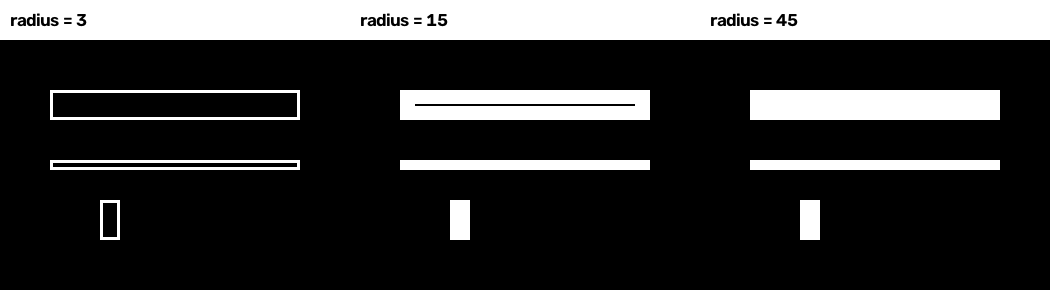

In [3]:
complex_test = np.ones((250, 350), dtype=np.uint8) * 200
complex_test[50:80, 50:300] = 40
complex_test[120:130, 50:300] = 40
complex_test[160:200, 100:120] = 40

radii = [3, 15, 45]
cell_images = []
for r in radii:
    res = adaptive_threshold(complex_test, radius=r, method='bradley', t=0.15)
    bgr = cv2.cvtColor(res, cv2.COLOR_GRAY2BGR)
    canvas = np.ones((290, 350, 3), dtype=np.uint8) * 255
    canvas[40:, :] = bgr
    cv2.putText(canvas, f"radius = {r}", (10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2, cv2.LINE_AA)
    cell_images.append(canvas)

radius_effect_path = img_dir / "radius_effect.png"
cv2.imwrite(str(radius_effect_path), np.hstack(cell_images))
display(Image(str(radius_effect_path)))

t_list = [0.10, 0.15, 0.20]
k_list = [0.20, 0.34, 0.50]
for t_val in t_list:
    _ = adaptive_threshold(complex_test, radius=15, method='bradley', t=t_val)
for k_val in k_list:
    _ = adaptive_threshold(complex_test, radius=15, method='sauvola', k=k_val)

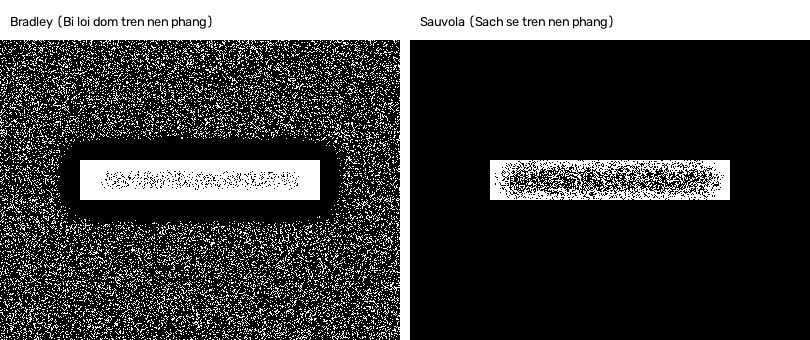

In [4]:
H, W = 300, 400
flat_img = np.ones((H, W), dtype=np.uint8) * 180
flat_img[120:160, 80:320] = 70

np.random.seed(100)
noise = np.random.randint(-25, 25, (H, W), dtype=np.int32)
flat_img = np.clip(flat_img.astype(np.int32) + noise, 0, 255).astype(np.uint8)

res_bradley = adaptive_threshold(flat_img, radius=25, method='bradley', t=0.08)
res_sauvola = adaptive_threshold(flat_img, radius=25, method='sauvola', k=0.50)

comp_flat_path = img_dir / "comparison_flat_background.png"
c_b = cv2.cvtColor(res_bradley, cv2.COLOR_GRAY2BGR)
c_s = cv2.cvtColor(res_sauvola, cv2.COLOR_GRAY2BGR)

canvas_flat = np.ones((340, 810, 3), dtype=np.uint8) * 255
canvas_flat[40:, 0:400] = c_b
canvas_flat[40:, 410:810] = c_s
cv2.putText(canvas_flat, "Bradley (Bi loi dom tren nen phang)", (10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1, cv2.LINE_AA)
cv2.putText(canvas_flat, "Sauvola (Sach se tren nen phang)", (420, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1, cv2.LINE_AA)

cv2.imwrite(str(comp_flat_path), canvas_flat)
display(Image(str(comp_flat_path)))

Radius     | Integral O(1)   | Separable O(r)  | Direct O(r^2)  
-----------------------------------------------------------------
1          | 0.001710        | 0.000208        | 0.184085       
2          | 0.000995        | 0.000158        | 0.241411       
4          | 0.002312        | 0.000221        | 0.206016       
8          | 0.001615        | 0.000151        | 0.207394       
16         | 0.002345        | 0.000354        | 0.170037       
32         | 0.001410        | 0.000348        | 0.250118       


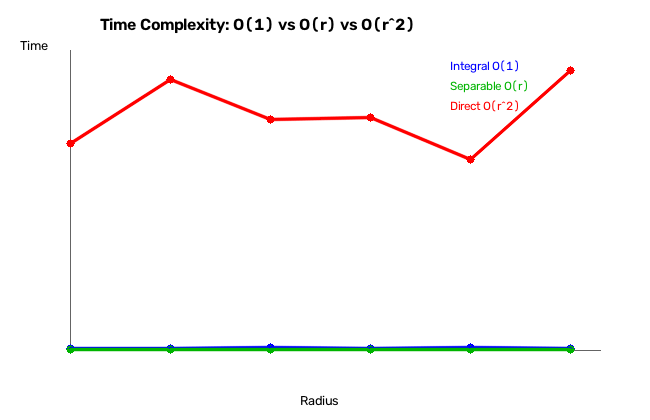

In [5]:
radii_list = [1, 2, 4, 8, 16, 32]
t_integral, t_separable, t_direct = [], [], []
dummy_img = np.random.randint(0, 256, (120, 120), dtype=np.uint8)

print(f"{'Radius':<10} | {'Integral O(1)':<15} | {'Separable O(r)':<15} | {'Direct O(r^2)':<15}")
print("-" * 65)

for r in radii_list:
    w = 2 * r + 1
    start = time.time()
    _ = local_mean_std(dummy_img, radius=r)
    t1 = time.time() - start
    t_integral.append(t1)
    
    kernel_1d = np.ones(w, dtype=np.float32) / w
    start = time.time()
    _ = cv2.sepFilter2D(dummy_img.astype(np.float32), -1, kernel_1d, kernel_1d)
    t2 = time.time() - start
    t_separable.append(t2)
    
    kernel_2d = np.outer(kernel_1d, kernel_1d)
    start = time.time()
    _ = convolve2d(dummy_img.astype(np.float32), kernel_2d)
    t3 = time.time() - start
    t_direct.append(t3)
    
    print(f"{r:<10} | {t1:<15.6f} | {t2:<15.6f} | {t3:<15.6f}")

chart_img = np.ones((420, 650, 3), dtype=np.uint8) * 255
cv2.putText(chart_img, "Time Complexity: O(1) vs O(r) vs O(r^2)", (100, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 2, cv2.LINE_AA)
cv2.putText(chart_img, "Radius", (300, 405), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1, cv2.LINE_AA)
cv2.putText(chart_img, "Time", (20, 50), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1, cv2.LINE_AA)

cv2.line(chart_img, (70, 350), (600, 350), (100, 100, 100), 1)
cv2.line(chart_img, (70, 50), (70, 350), (100, 100, 100), 1)

max_t = max(max(t_integral), max(t_separable), max(t_direct)) if max(max(t_integral), max(t_separable), max(t_direct)) > 0 else 1

pts_int, pts_sep, pts_dir = [], [], []
for i, r in enumerate(radii_list):
    px = int(70 + (i / (len(radii_list) - 1)) * 500)
    py_i = int(350 - (t_integral[i] / max_t) * 280)
    py_s = int(350 - (t_separable[i] / max_t) * 280)
    py_d = int(350 - (t_direct[i] / max_t) * 280)
    
    pts_int.append((px, py_i))
    pts_sep.append((px, py_s))
    pts_dir.append((px, py_d))
    
    cv2.circle(chart_img, (px, py_i), 4, (255, 0, 0), -1)
    cv2.circle(chart_img, (px, py_s), 4, (0, 180, 0), -1)
    cv2.circle(chart_img, (px, py_d), 4, (0, 0, 255), -1)

for i in range(len(pts_int) - 1):
    cv2.line(chart_img, pts_int[i], pts_int[i+1], (255, 0, 0), 2, cv2.LINE_AA)
    cv2.line(chart_img, pts_sep[i], pts_sep[i+1], (0, 180, 0), 2, cv2.LINE_AA)
    cv2.line(chart_img, pts_dir[i], pts_dir[i+1], (0, 0, 255), 2, cv2.LINE_AA)

cv2.putText(chart_img, "Integral O(1)", (450, 70), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1, cv2.LINE_AA)
cv2.putText(chart_img, "Separable O(r)", (450, 90), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 180, 0), 1, cv2.LINE_AA)
cv2.putText(chart_img, "Direct O(r^2)", (450, 110), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1, cv2.LINE_AA)

chart_path = img_dir / "time_complexity.png"
cv2.imwrite(str(chart_path), chart_img)
display(Image(str(chart_path)))